<a href="https://colab.research.google.com/github/Oleh12342/pattern-recognition-practice/blob/model-comparison/classification-mini-project/notebooks/PR04_Kulesh_O.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Підключення Google-Drive

In [1]:
from google.colab import drive
drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
from pathlib import Path

PROJECT_DIR = Path("/content/drive/MyDrive/classification-mini-project")
DATA_DIR    = PROJECT_DIR / "data"
MODELS_DIR  = PROJECT_DIR / "models"
REPORTS_DIR = PROJECT_DIR / "reports"

MODELS_DIR.mkdir(exist_ok=True)
REPORTS_DIR.mkdir(exist_ok=True)

print(list(DATA_DIR.iterdir()))

[PosixPath('/content/drive/MyDrive/classification-mini-project/data/processed.cleveland.data'), PosixPath('/content/drive/MyDrive/classification-mini-project/data/heart_disease.csv')]


## Створення heart_disease.csv
Готового файлу heart_disease.csv не було, тому я створив його самостійно з оригінального архіву UCI Heart Disease. Використано файл processed.cleveland.data.

In [3]:
import pandas as pd

columns = [
    "age", "sex", "cp", "trestbps", "chol", "fbs", "restecg",
    "thalach", "exang", "oldpeak", "slope", "ca", "thal", "num"
]

df = pd.read_csv(
    DATA_DIR / "processed.cleveland.data",
    header=None,
    names=columns,
    na_values="?"
)

df["target"] = (df["num"] > 0).astype(int)
df = df.drop(columns="num")

print(df.shape)
print(df["target"].value_counts())
print(df.isna().sum().sum())

df.to_csv(DATA_DIR / "heart_disease.csv", index=False)

(303, 14)
target
0    164
1    139
Name: count, dtype: int64
6


# Частина 1
Основна метрика: F1 для позитивного класу; додаткові: Recall, ROC AUC.

Імпорт бібліотек та константи

In [4]:
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression

RANDOM_STATE = 42

numeric_columns = ["age", "trestbps", "chol", "thalach", "oldpeak"]
categorical_columns = ["sex", "cp", "fbs", "restecg", "exang", "slope", "ca", "thal"]
target_column = "target"

Завантаження та аудит

In [5]:
df = pd.read_csv(DATA_DIR / "heart_disease.csv")

display(df.head())
print("Розмір:", df.shape)
print("\nТипи даних:")
print(df.dtypes)
print("\nПропуски по стовпцях:")
print(df.isna().sum())
print("\nРозподіл класів:")
print(df[target_column].value_counts())
print(df[target_column].value_counts(normalize=True).round(3))
print("\nДопустимі значення target:", sorted(df[target_column].unique()))

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,1
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


Розмір: (303, 14)

Типи даних:
age         float64
sex         float64
cp          float64
trestbps    float64
chol        float64
fbs         float64
restecg     float64
thalach     float64
exang       float64
oldpeak     float64
slope       float64
ca          float64
thal        float64
target        int64
dtype: object

Пропуски по стовпцях:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
target      0
dtype: int64

Розподіл класів:
target
0    164
1    139
Name: count, dtype: int64
target
0    0.541
1    0.459
Name: proportion, dtype: float64

Допустимі значення target: [np.int64(0), np.int64(1)]


In [6]:
audit = pd.DataFrame({
    "Характеристика": [
        "Кількість об'єктів", "Кількість вхідних ознак",
        "Числові ознаки", "Категоріальні ознаки",
        "Кількість пропусків", "Кількість класів", "Позитивний клас"
    ],
    "Значення": [
        df.shape[0], df.shape[1] - 1,
        ", ".join(numeric_columns), ", ".join(categorical_columns),
        int(df.isna().sum().sum()), df[target_column].nunique(), 1
    ]
})
display(audit)

,Характеристика,Значення
0,Кількість об'єктів,303
1,Кількість вхідних ознак,13
2,Числові ознаки,"age, trestbps, chol, thalach, oldpeak"
3,Категоріальні ознаки,"sex, cp, fbs, restecg, exang, slope, ca, thal"
4,Кількість пропусків,6
5,Кількість класів,2
6,Позитивний клас,1


X, y і єдиний split

In [7]:
X = df.drop(columns=target_column)
y = df[target_column]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Train:", X_train.shape, " Test:", X_test.shape)
print("Частка класу 1 у train:", round(y_train.mean(), 3))
print("Частка класу 1 у test: ", round(y_test.mean(), 3))

Train: (242, 13)  Test: (61, 13)
Частка класу 1 у train: 0.459
Частка класу 1 у test:  0.459


Єдина схема крос-валідації


In [8]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

Препроцесинг

In [9]:
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

numeric_pipeline_scaled = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

numeric_pipeline_raw = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", "passthrough")
])

preprocessor_scaled = ColumnTransformer([
    ("num", numeric_pipeline_scaled, numeric_columns),
    ("cat", categorical_pipeline, categorical_columns)
])

preprocessor_raw = ColumnTransformer([
    ("num", numeric_pipeline_raw, numeric_columns),
    ("cat", categorical_pipeline, categorical_columns)
])

Два Pipeline логістичної регресії та порівняння за CV

In [10]:
lr_scaled = Pipeline([
    ("preprocessor", preprocessor_scaled),
    ("classifier", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE))
])

lr_raw = Pipeline([
    ("preprocessor", preprocessor_raw),
    ("classifier", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE))
])

scoring = {"f1": "f1", "roc_auc": "roc_auc", "recall": "recall"}

def run_cv(pipeline, name):
    with warnings.catch_warnings(record=True) as w:
        warnings.simplefilter("always")
        res = cross_validate(pipeline, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
        n_warn = sum("converge" in str(x.message).lower() for x in w)
    fitted = pipeline.fit(X_train, y_train)
    n_iter = int(fitted.named_steps["classifier"].n_iter_[0])
    return {
        "Модель": name,
        "CV F1": res["test_f1"].mean(), "F1 std": res["test_f1"].std(),
        "CV ROC AUC": res["test_roc_auc"].mean(), "AUC std": res["test_roc_auc"].std(),
        "CV Recall": res["test_recall"].mean(),
        "Ітерацій (train)": n_iter,
        "Попередж. збіжності": n_warn,
    }

scale_cmp = pd.DataFrame([
    run_cv(lr_raw, "LogReg без стандартизації"),
    run_cv(lr_scaled, "LogReg зі стандартизацією"),
]).round(4)
display(scale_cmp)

,Модель,CV F1,F1 std,CV ROC AUC,AUC std,CV Recall,Ітерацій (train),Попередж. збіжності
0,LogReg без стандартизації,0.8245,0.0069,0.8997,0.0157,0.7834,1238,0
1,LogReg зі стандартизацією,0.8245,0.0069,0.9025,0.0144,0.7834,18,0


L1- і L2-регуляризація

In [11]:
param_grid = [
    {"classifier__penalty": ["l1", "l2"],
     "classifier__C": [0.01, 0.1, 1, 10, 100]}
]

lr_grid_pipe = Pipeline([
    ("preprocessor", preprocessor_scaled),
    ("classifier", LogisticRegression(solver="liblinear", max_iter=2000, random_state=RANDOM_STATE))
])

grid_lr = GridSearchCV(
    lr_grid_pipe, param_grid,
    scoring="f1", cv=cv, n_jobs=-1, refit=True,
    return_train_score=False
)
grid_lr.fit(X_train, y_train)

print("Найкращі параметри:", grid_lr.best_params_)
print("Найкращий CV F1:", round(grid_lr.best_score_, 4))

lr_results = (pd.DataFrame(grid_lr.cv_results_)
    [["param_classifier__penalty", "param_classifier__C",
      "mean_test_score", "std_test_score", "rank_test_score"]]
    .rename(columns={
        "param_classifier__penalty": "penalty",
        "param_classifier__C": "C",
        "mean_test_score": "CV F1",
        "std_test_score": "CV F1 std",
        "rank_test_score": "rank"})
    .sort_values("rank"))
display(lr_results.round(4))

Найкращі параметри: {'classifier__C': 10, 'classifier__penalty': 'l2'}
Найкращий CV F1: 0.8363


,penalty,C,CV F1,CV F1 std,rank
7,l2,10.00,0.8363,0.0127,1
8,l1,100.00,0.8363,0.0127,1
9,l2,100.00,0.8363,0.0127,1
6,l1,10.00,0.8321,0.0108,4
5,l2,1.00,0.8245,0.0069,5
3,l2,0.10,0.8140,0.0299,6
4,l1,1.00,0.8123,0.0173,7
2,l1,0.10,0.7926,0.0306,8
1,l2,0.01,0.7658,0.0171,9
0,l1,0.01,0.0000,0.0000,10


Графік залежності CV F1 від C

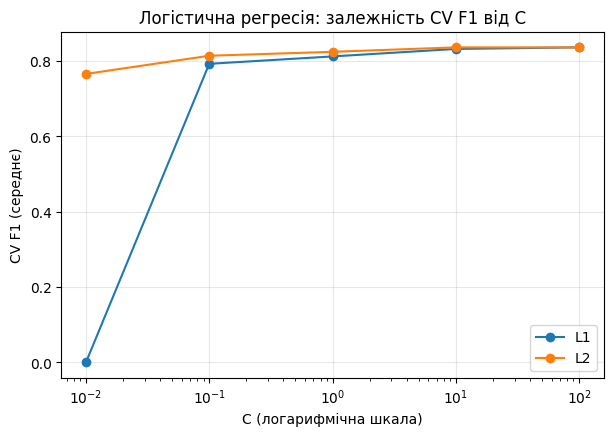

In [12]:
plt.figure(figsize=(7, 4.5))
for pen in ["l1", "l2"]:
    sub = lr_results[lr_results["penalty"] == pen].sort_values("C")
    plt.plot(sub["C"].astype(float), sub["CV F1"], marker="o", label=pen.upper())
plt.xscale("log")
plt.xlabel("C (логарифмічна шкала)")
plt.ylabel("CV F1 (середнє)")
plt.title("Логістична регресія: залежність CV F1 від C")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

Топ-5 коефіцієнтів найкращої моделі

In [13]:
best_lr = grid_lr.best_estimator_
feature_names = best_lr.named_steps["preprocessor"].get_feature_names_out()
coefs = best_lr.named_steps["classifier"].coef_[0]

coef_df = pd.DataFrame({
    "Ознака": feature_names,
    "Коефіцієнт": coefs,
    "|Коефіцієнт|": np.abs(coefs)
}).sort_values("|Коефіцієнт|", ascending=False)

display(coef_df.head(5).round(4))

,Ознака,Коефіцієнт,|Коефіцієнт|
21,cat__ca_0.0,-1.9262,1.9262
10,cat__cp_4.0,1.1886,1.1886
27,cat__thal_7.0,0.9779,0.9779
7,cat__cp_1.0,-0.8921,0.8921
5,cat__sex_0.0,-0.8802,0.8802


## Висновок
Побудовано Pipeline (імпутація, стандартизація, one-hot-кодування) і досліджено логістичну регресію за 5-кратною StratifiedKFold лише на train; тестова вибірка не використовувалася.

- **Масштабування:** CV F1 (0,8245) і Recall (0,7834) не змінилися, ROC AUC майже однаковий (0,9025 проти 0,8997). Різниця у збіжності: 18 ітерацій зі стандартизацією проти 1238 без неї, тому далі використовуємо стандартизацію.
- **Регуляризація:** найкраща конфігурація за CV: L2, C = 10 (CV F1 = 0,8363, std = 0,0127). За C = 0,01 L1 занулює всі коефіцієнти (F1 = 0, недонавчання), а за C ≥ 10 якість виходить на плато.
- **Коефіцієнти:** найбільші за модулем мають ca = 0 (-1,93), cp = 4 (+1,19), thal = 7 (+0,98), cp = 1 (-0,89), sex = ` (-0,88). Вони описують закономірності в даних, але не доводять причинного впливу.

# Частина 2

Імпорти, допоміжна функція і результат логістичної регресії з частини 1

In [14]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis, QuadraticDiscriminantAnalysis
from sklearn.model_selection import cross_val_predict

cv_rows = []

def cv_summary(pipeline, name, params="", n_jobs=-1):
    res = cross_validate(pipeline, X_train, y_train, cv=cv, scoring=scoring, n_jobs=n_jobs)
    return {
        "Модель": name, "Параметри": params,
        "CV F1": res["test_f1"].mean(), "CV F1 std": res["test_f1"].std(),
        "CV Recall": res["test_recall"].mean(),
        "CV ROC AUC": res["test_roc_auc"].mean(),
        "Час fit, с": res["fit_time"].mean(),
    }

cv_rows.append(cv_summary(grid_lr.best_estimator_, "Logistic Regression", "L2, C=10"))
display(pd.DataFrame(cv_rows).round(4))

,Модель,Параметри,CV F1,CV F1 std,CV Recall,CV ROC AUC,"Час fit, с"
0,Logistic Regression,"L2, C=10",0.8363,0.0127,0.8016,0.9002,0.0937


k-NN

In [15]:
def make_knn(preprocessor, **kw):
    return Pipeline([("preprocessor", preprocessor),
                     ("classifier", KNeighborsClassifier(**kw))])

knn_scale_cmp = pd.DataFrame([
    cv_summary(make_knn(preprocessor_raw, n_neighbors=5), "k-NN без стандартизації", "k=5"),
    cv_summary(make_knn(preprocessor_scaled, n_neighbors=5), "k-NN зі стандартизацією", "k=5"),
])
display(knn_scale_cmp.round(4))

,Модель,Параметри,CV F1,CV F1 std,CV Recall,CV ROC AUC,"Час fit, с"
0,k-NN без стандартизації,k=5,0.5120,0.0134,0.4866,0.6419,0.0846
1,k-NN зі стандартизацією,k=5,0.7989,0.0426,0.7826,0.8712,0.0861


Вибір k (3, 5, 7, 9, 11, 15) і графік

,k,CV F1,CV F1 std,CV ROC AUC,CV Recall
0,3,0.8042,0.0272,0.8709,0.8008
1,5,0.7989,0.0426,0.8712,0.7826
2,7,0.7942,0.0184,0.8721,0.7656
3,9,0.7872,0.0294,0.8744,0.7557
4,11,0.7791,0.0273,0.8806,0.7375
5,15,0.7651,0.0246,0.8729,0.7209


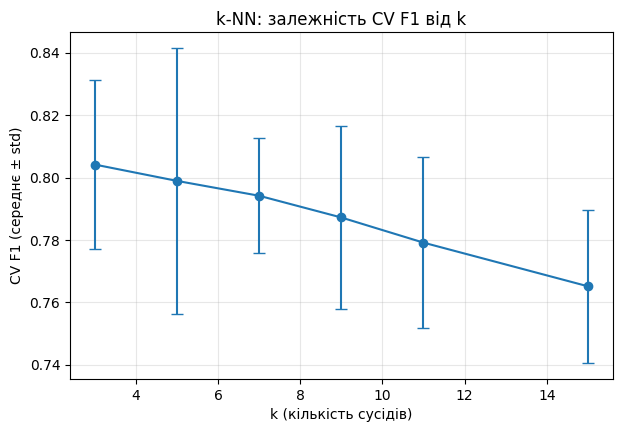

Найкраще k за CV F1: 3


In [16]:
k_values = [3, 5, 7, 9, 11, 15]
knn_k_df = pd.DataFrame([
    {**cv_summary(make_knn(preprocessor_scaled, n_neighbors=k), f"k-NN k={k}", f"k={k}"), "k": k}
    for k in k_values
])
display(knn_k_df[["k", "CV F1", "CV F1 std", "CV ROC AUC", "CV Recall"]].round(4))

plt.figure(figsize=(7, 4.5))
plt.errorbar(knn_k_df["k"], knn_k_df["CV F1"], yerr=knn_k_df["CV F1 std"],
             marker="o", capsize=4)
plt.xlabel("k (кількість сусідів)")
plt.ylabel("CV F1 (середнє ± std)")
plt.title("k-NN: залежність CV F1 від k")
plt.grid(alpha=0.3)
plt.show()

best_k = int(knn_k_df.loc[knn_k_df["CV F1"].idxmax(), "k"])
print("Найкраще k за CV F1:", best_k)

Евклідова та манхеттенська відстань для найкращого k

In [17]:
dist_rows = []
for metric, label in [("euclidean", "Евклідова"), ("manhattan", "Мангеттенська")]:
    row = cv_summary(make_knn(preprocessor_scaled, n_neighbors=best_k, metric=metric),
                     f"k-NN ({label})", f"k={best_k}, metric={metric}")
    row["Міра відстані"] = label
    dist_rows.append(row)

dist_df = pd.DataFrame(dist_rows)
display(dist_df[["Міра відстані", "CV F1", "CV F1 std", "CV ROC AUC"]].round(4))

best_knn_row = dist_df.loc[dist_df["CV F1"].idxmax()]
best_metric = "euclidean" if best_knn_row["Міра відстані"] == "Евклідова" else "manhattan"
best_knn_pipe = make_knn(preprocessor_scaled, n_neighbors=best_k, metric=best_metric)
cv_rows.append(cv_summary(best_knn_pipe, "k-NN", f"k={best_k}, metric={best_metric}"))
print("Найкраща k-NN:", best_k, best_metric)

,Міра відстані,CV F1,CV F1 std,CV ROC AUC
0,Евклідова,0.8042,0.0272,0.8709
1,Мангеттенська,0.8175,0.0304,0.8768


Найкраща k-NN: 3 manhattan


GaussianNB, LDA, QDA (з фіксацією попереджень)

In [18]:
def cv_with_warnings(pipeline, name, params=""):
    with warnings.catch_warnings(record=True) as w:
        warnings.simplefilter("always")
        row = cv_summary(pipeline, name, params, n_jobs=1)
    row["Попередж."] = len(w)
    msgs = sorted({f"{x.category.__name__}: {str(x.message)[:100]}" for x in w})
    return row, msgs

def make_prob(clf):
    return Pipeline([("preprocessor", preprocessor_scaled), ("classifier", clf)])

prob_rows, prob_msgs = [], {}
for name, clf, params in [
    ("GaussianNB", GaussianNB(), "–"),
    ("LDA", LinearDiscriminantAnalysis(), "solver=svd"),
]:
    row, msgs = cv_with_warnings(make_prob(clf), name, params)
    prob_rows.append(row); prob_msgs[name] = msgs

for rp in [0, 0.01, 0.1]:
    row, msgs = cv_with_warnings(
        make_prob(QuadraticDiscriminantAnalysis(reg_param=rp)),
        f"QDA reg_param={rp}", f"reg_param={rp}")
    prob_rows.append(row); prob_msgs[f"QDA reg_param={rp}"] = msgs

prob_df = pd.DataFrame(prob_rows)
display(prob_df[["Модель", "CV F1", "CV F1 std", "CV Recall", "CV ROC AUC", "Попередж."]].round(4))

for k, v in prob_msgs.items():
    print(k, "->", v if v else "без попереджень")

,Модель,CV F1,CV F1 std,CV Recall,CV ROC AUC,Попередж.
0,GaussianNB,0.7495,0.0215,0.8458,0.8773,0
1,LDA,0.8128,0.0257,0.7656,0.8993,0
2,QDA reg_param=0,0.5709,0.1433,0.8186,0.7607,10
3,QDA reg_param=0.01,0.7709,0.0440,0.7743,0.8343,0
4,QDA reg_param=0.1,0.7962,0.0271,0.7743,0.8680,0


GaussianNB -> без попереджень
LDA -> без попереджень
QDA reg_param=0 -> ['LinAlgWarning: The covariance matrix of class 0 is not full rank. Increasing the value of parameter `reg_param` mig', 'LinAlgWarning: The covariance matrix of class 1 is not full rank. Increasing the value of parameter `reg_param` mig']
QDA reg_param=0.01 -> без попереджень
QDA reg_param=0.1 -> без попереджень


In [19]:
qda_df = prob_df[prob_df["Модель"].str.startswith("QDA")]
best_qda_row = qda_df.loc[qda_df["CV F1"].idxmax()]
best_rp = float(best_qda_row["Параметри"].split("=")[1])

cands = pd.concat([prob_df[prob_df["Модель"].isin(["GaussianNB", "LDA"])],
                   best_qda_row.to_frame().T])
cands["CV F1"] = cands["CV F1"].astype(float)
best_prob_row = cands.loc[cands["CV F1"].idxmax()]
print("Найкраща ймовірнісна модель:", best_prob_row["Модель"], round(best_prob_row["CV F1"], 4))

Найкраща ймовірнісна модель: LDA 0.8128


GaussianNB: розподіли числових ознак за класами

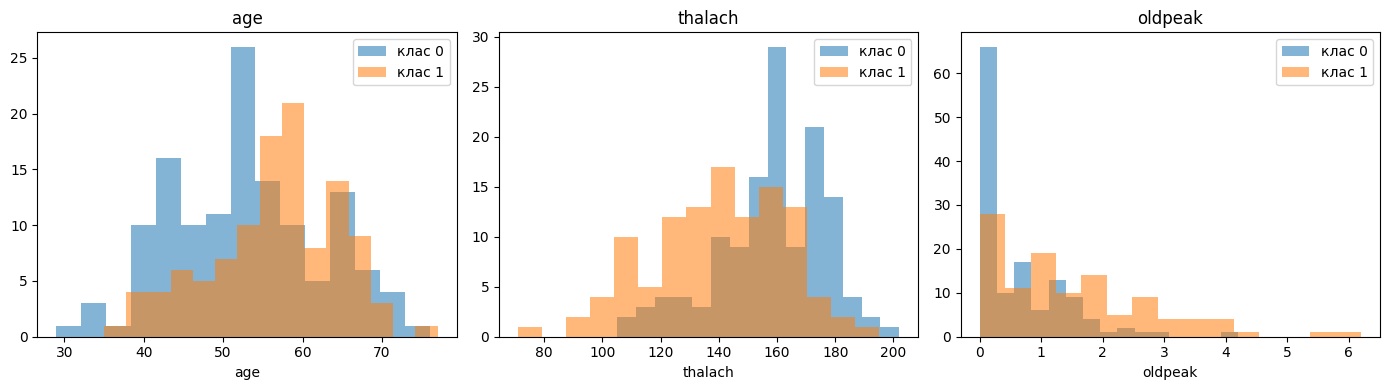

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col in zip(axes, ["age", "thalach", "oldpeak"]):
    for cls, color in [(0, "tab:blue"), (1, "tab:orange")]:
        ax.hist(X_train.loc[y_train == cls, col].dropna(), bins=15,
                alpha=0.55, label=f"клас {cls}", color=color)
    ax.set_title(col); ax.set_xlabel(col); ax.legend()
plt.tight_layout()
plt.show()

Позавибіркові (OOF) ймовірності для кількох train-об'єктів

In [21]:
oof_models = {
    "GaussianNB OOF": make_prob(GaussianNB()),
    "LDA OOF": make_prob(LinearDiscriminantAnalysis()),
    "QDA OOF": make_prob(QuadraticDiscriminantAnalysis(reg_param=best_rp)),
}

oof = {}
for name, pipe in oof_models.items():
    oof[name] = cross_val_predict(pipe, X_train, y_train, cv=cv,
                                  method="predict_proba", n_jobs=1)[:, 1]

oof_df = pd.DataFrame(oof, index=X_train.index)
oof_df.insert(0, "Справжній клас", y_train)
display(oof_df.sample(8, random_state=RANDOM_STATE).round(3))

,Справжній клас,GaussianNB OOF,LDA OOF,QDA OOF
199,1,0.005,0.013,0.191
55,1,1.000,0.998,1.000
110,1,1.000,0.819,0.789
192,1,1.000,0.877,0.951
173,0,0.477,0.251,0.017
98,0,0.002,0.276,0.079
49,0,0.996,0.081,0.123
78,0,0.000,0.103,0.004


Підсумок частини 2 і збереження кандидатів

In [22]:
best_prob_name = best_prob_row["Модель"]
best_prob_params = best_prob_row["Параметри"]

if best_prob_name.startswith("QDA"):
    best_prob_pipe = make_prob(QuadraticDiscriminantAnalysis(reg_param=best_rp))
elif best_prob_name == "LDA":
    best_prob_pipe = make_prob(LinearDiscriminantAnalysis())
else:
    best_prob_pipe = make_prob(GaussianNB())

cv_rows.append(cv_summary(best_prob_pipe, best_prob_name.split(" ")[0], best_prob_params, n_jobs=1))
display(pd.DataFrame(cv_rows).round(4))

,Модель,Параметри,CV F1,CV F1 std,CV Recall,CV ROC AUC,"Час fit, с"
0,Logistic Regression,"L2, C=10",0.8363,0.0127,0.8016,0.9002,0.0937
1,k-NN,"k=3, metric=manhattan",0.8175,0.0304,0.7917,0.8768,0.0529
2,LDA,solver=svd,0.8128,0.0257,0.7656,0.8993,0.0280


## Висновок
Усі моделі побудовано як Pipeline з однією схемою StratifiedKFold(5) лише на train; тестова вибірка не використовувалася.

- **k-NN:** стандартизація критична: CV F1 зріс з 0,512 до 0,799 (k=5), бо без неї ознаки з великим діапазоном (chol, thalach) домінують у відстані. Найкраще k = 3 (F1 = 0,804), далі F1 монотонно падає до 0,765 (k=15); різниця між сусідніми k менша за std між фолдами. Манхеттенська відстань (F1 = 0,8175) трохи краща за евклідову (0,8042), але різниця в межах шуму. Найкраща k-NN: k=3, manhattan.
- **Ймовірнісні моделі:** найкраща LDA (F1 = 0,8128, ROC AUC = 0,8993, std = 0,026, без попереджень). GaussianNB слабша (F1 = 0,7495) через порушення нормальності (oldpeak) та залежність ознак, але має найвищий Recall (0,846).
- **QDA:** при reg_param=0 нестабільна: 10 попереджень про виродження коваріаційної матриці, F1 = 0,571, std = 0,143. Причина: стовпці one-hot-кодування лінійно залежні. При reg_param=0,01 і 0,1 попередження зникли, найкращий результат за 0,1 (F1 = 0,7962).
- **OOF-ймовірності:** GaussianNB дає надто впевнені, часто помилкові оцінки (наприклад, 0,996 для об'єкта класу 0), LDA стриманіша й надійніша.

# Частина 3

Імпорт бібліотеки

In [23]:
from sklearn.svm import SVC

Лінійна SVM

In [24]:
def make_svm(**kw):
    return Pipeline([("preprocessor", preprocessor_scaled),
                     ("classifier", SVC(random_state=RANDOM_STATE, **kw))])

lin_rows = []
for C in [0.1, 1, 10]:
    row = cv_summary(make_svm(kernel="linear", C=C), f"Linear SVM C={C}", f"kernel=linear, C={C}")
    row["C"] = C
    lin_rows.append(row)

lin_df = pd.DataFrame(lin_rows)
display(lin_df[["C", "CV F1", "CV F1 std", "CV Recall", "CV ROC AUC", "Час fit, с"]].round(4))

,C,CV F1,CV F1 std,CV Recall,CV ROC AUC,"Час fit, с"
0,0.1,0.7962,0.0536,0.7375,0.9047,0.0582
1,1.0,0.8025,0.0309,0.7747,0.8980,0.0631
2,10.0,0.8000,0.0263,0.7747,0.8968,0.1272


RBF-SVM

In [25]:
rbf_rows = []
for C in [0.1, 1, 10]:
    for gamma in ["scale", 0.01, 0.1]:
        row = cv_summary(make_svm(kernel="rbf", C=C, gamma=gamma),
                         f"RBF C={C}, gamma={gamma}", f"kernel=rbf, C={C}, gamma={gamma}")
        row["C"] = C; row["gamma"] = str(gamma)
        rbf_rows.append(row)

rbf_df = pd.DataFrame(rbf_rows)
display(rbf_df[["C", "gamma", "CV F1", "CV F1 std", "CV ROC AUC"]].round(4))

,C,gamma,CV F1,CV F1 std,CV ROC AUC
0,0.1,scale,0.7630,0.0159,0.8855
1,0.1,0.01,0.2461,0.1129,0.8821
2,0.1,0.1,0.7652,0.0174,0.8848
3,1.0,scale,0.7893,0.0271,0.8884
4,1.0,0.01,0.7951,0.0292,0.8957
5,1.0,0.1,0.7893,0.0271,0.8867
6,10.0,scale,0.7480,0.0228,0.8229
7,10.0,0.01,0.8270,0.0330,0.8968
8,10.0,0.1,0.7558,0.0328,0.8230


GridSearchCV (linear + RBF)

In [26]:
svm_pipe = Pipeline([
    ("preprocessor", preprocessor_scaled),
    ("classifier", SVC(random_state=RANDOM_STATE))
])

param_grid_svm = [
    {"classifier__kernel": ["linear"],
     "classifier__C": [0.1, 1, 10]},
    {"classifier__kernel": ["rbf"],
     "classifier__C": [0.1, 1, 10],
     "classifier__gamma": ["scale", 0.01, 0.1]},
]

grid_svm = GridSearchCV(
    svm_pipe, param_grid_svm,
    scoring="f1", cv=cv, n_jobs=-1, refit=True
)
grid_svm.fit(X_train, y_train)

print("Найкращі параметри:", grid_svm.best_params_)
print("Найкращий CV F1:", round(grid_svm.best_score_, 4))

svm_results = (pd.DataFrame(grid_svm.cv_results_)
    [["param_classifier__kernel", "param_classifier__C", "param_classifier__gamma",
      "mean_test_score", "std_test_score", "rank_test_score"]]
    .rename(columns={
        "param_classifier__kernel": "kernel",
        "param_classifier__C": "C",
        "param_classifier__gamma": "gamma",
        "mean_test_score": "CV F1",
        "std_test_score": "CV F1 std",
        "rank_test_score": "rank"})
    .sort_values("rank"))
display(svm_results.head(5).round(4))

Найкращі параметри: {'classifier__C': 10, 'classifier__gamma': 0.01, 'classifier__kernel': 'rbf'}
Найкращий CV F1: 0.827


,kernel,C,gamma,CV F1,CV F1 std,rank
10,rbf,10.0,0.01,0.8270,0.0330,1
1,linear,1.0,NaN,0.8025,0.0309,2
2,linear,10.0,NaN,0.8000,0.0263,3
0,linear,0.1,NaN,0.7962,0.0536,4
7,rbf,1.0,0.01,0.7951,0.0292,5


Linear vs RBF: найкраща конфігурація кожного ядра

In [27]:
best_lin = svm_results[svm_results["kernel"] == "linear"].iloc[0]
best_rbf = svm_results[svm_results["kernel"] == "rbf"].iloc[0]
print("Найкраща linear:", dict(best_lin[["C"]]), round(best_lin["CV F1"], 4))
print("Найкраща RBF:   ", dict(best_rbf[["C", "gamma"]]), round(best_rbf["CV F1"], 4))

def svm_from_row(r):
    kw = dict(kernel=r["kernel"], C=float(r["C"]))
    if r["kernel"] == "rbf":
        g = r["gamma"]
        kw["gamma"] = g if g == "scale" else float(g)
    return make_svm(**kw)

cmp_df = pd.DataFrame([
    cv_summary(svm_from_row(best_lin), "Linear SVM", f"C={best_lin['C']}"),
    cv_summary(svm_from_row(best_rbf), "RBF SVM", f"C={best_rbf['C']}, gamma={best_rbf['gamma']}"),
])
display(cmp_df.round(4))

Найкраща linear: {'C': np.float64(1.0)} 0.8025
Найкраща RBF:    {'C': np.float64(10.0), 'gamma': 0.01} 0.827


,Модель,Параметри,CV F1,CV F1 std,CV Recall,CV ROC AUC,"Час fit, с"
0,Linear SVM,C=1.0,0.8025,0.0309,0.7747,0.8980,0.0337
1,RBF SVM,"C=10.0, gamma=0.01",0.8270,0.0330,0.7830,0.8968,0.0257


Фіксація найкращої SVM

In [28]:
best_svm_pipe = grid_svm.best_estimator_
bp = grid_svm.best_params_
params_str = ", ".join(f"{k.split('__')[1]}={v}" for k, v in bp.items())

cv_rows.append(cv_summary(
    Pipeline([("preprocessor", preprocessor_scaled),
              ("classifier", SVC(random_state=RANDOM_STATE,
                                 **{k.split('__')[1]: v for k, v in bp.items()}))]),
    "SVM", params_str))
display(pd.DataFrame(cv_rows).round(4))

,Модель,Параметри,CV F1,CV F1 std,CV Recall,CV ROC AUC,"Час fit, с"
0,Logistic Regression,"L2, C=10",0.8363,0.0127,0.8016,0.9002,0.0937
1,k-NN,"k=3, metric=manhattan",0.8175,0.0304,0.7917,0.8768,0.0529
2,LDA,solver=svd,0.8128,0.0257,0.7656,0.8993,0.0280
3,SVM,"C=10, gamma=0.01, kernel=rbf",0.8270,0.0330,0.7830,0.8968,0.0257


## Висновок
SVM побудовано як Pipeline зі стандартизацією; пошук параметрів виконано через GridSearchCV (5-кратна StratifiedKFold, метрика F1) лише на train; тестова вибірка не використовувалася.

- **Лінійна SVM:** якість майже не залежить від C (CV F1 ≈ 0,80 для C = 0,1; 1; 10), найкраще C = 1 (F1 = 0,8025).
- **RBF-SVM:** якість сильно залежить від C і gamma. За C = 0,1 і gamma = 0,01 модель недонавчена (F1 = 0,246), за C = 10 і gamma ≥ 0,1 спостерігається перенавчання (F1 ≈ 0,75, ROC AUC падає до 0,82). Найкраща конфігурація: C = 10, gamma = 0,01.
- **Вибір ядра:** найкраща SVM за CV: RBF, C = 10, gamma = 0,01 (F1 = 0,8270, std = 0,033, ROC AUC = 0,8968). Перевага над лінійною SVM (F1 = 0,8025, ROC AUC = 0,8980) менша за std між фолдами, тобто статистично незначуща.

# Частина 4

Імпорти

In [29]:
import joblib
from sklearn.metrics import (roc_curve, roc_auc_score, confusion_matrix,
                             ConfusionMatrixDisplay, accuracy_score,
                             precision_score, recall_score, f1_score)

## Правило вибору фінальної моделі
Основна метрика: CV F1. Фінальною обирається модель з найвищим CV F1. Якщо різниця між моделями мала, враховую CV Recall, ROC AUC, стабільність (std) і простоту моделі. Test для вибору не використовується.

Єдина таблиця кандидатів (лише CV)

In [30]:
cv_rows.append(cv_summary(make_prob(GaussianNB()), "GaussianNB", "–", n_jobs=1))
cv_rows.append(cv_summary(make_prob(QuadraticDiscriminantAnalysis(reg_param=best_rp)),
                          "QDA", f"reg_param={best_rp}", n_jobs=1))

cv_table = pd.DataFrame(cv_rows)
order = ["Logistic Regression", "k-NN", "GaussianNB", "LDA", "QDA", "SVM"]
cv_table["Модель"] = pd.Categorical(cv_table["Модель"], order, ordered=True)
cv_table = cv_table.sort_values("Модель").reset_index(drop=True)
display(cv_table.round(4))

cv_table.to_csv(REPORTS_DIR / "cv_model_comparison.csv", index=False)

,Модель,Параметри,CV F1,CV F1 std,CV Recall,CV ROC AUC,"Час fit, с"
0,Logistic Regression,"L2, C=10",0.8363,0.0127,0.8016,0.9002,0.0937
1,k-NN,"k=3, metric=manhattan",0.8175,0.0304,0.7917,0.8768,0.0529
2,GaussianNB,–,0.7495,0.0215,0.8458,0.8773,0.0164
3,LDA,solver=svd,0.8128,0.0257,0.7656,0.8993,0.0280
4,QDA,reg_param=0.1,0.7962,0.0271,0.7743,0.8680,0.0155
5,SVM,"C=10, gamma=0.01, kernel=rbf",0.8270,0.0330,0.7830,0.8968,0.0257


Спільні CV ROC-криві (OOF на train)

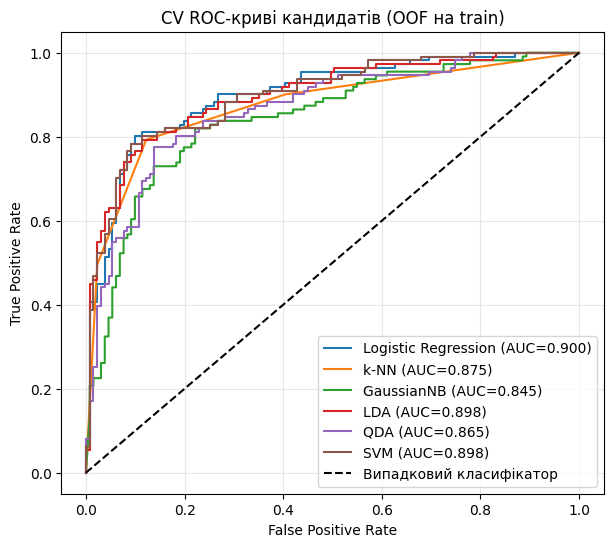

In [31]:
candidates = {
    "Logistic Regression": grid_lr.best_estimator_,
    "k-NN": best_knn_pipe,
    "GaussianNB": make_prob(GaussianNB()),
    "LDA": make_prob(LinearDiscriminantAnalysis()),
    "QDA": make_prob(QuadraticDiscriminantAnalysis(reg_param=best_rp)),
    "SVM": best_svm_pipe,
}

def oof_scores(pipe):
    method = "decision_function" if isinstance(pipe.named_steps["classifier"], SVC) else "predict_proba"
    s = cross_val_predict(pipe, X_train, y_train, cv=cv, method=method, n_jobs=1)
    return s[:, 1] if method == "predict_proba" else s

plt.figure(figsize=(7, 6))
for name, pipe in candidates.items():
    s = oof_scores(pipe)
    fpr, tpr, _ = roc_curve(y_train, s)
    plt.plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(y_train, s):.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Випадковий класифікатор")
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
plt.title("CV ROC-криві кандидатів (OOF на train)")
plt.legend(loc="lower right"); plt.grid(alpha=0.3)
plt.show()

CV-матриці помилок (LogReg, k-NN, LDA, SVM)

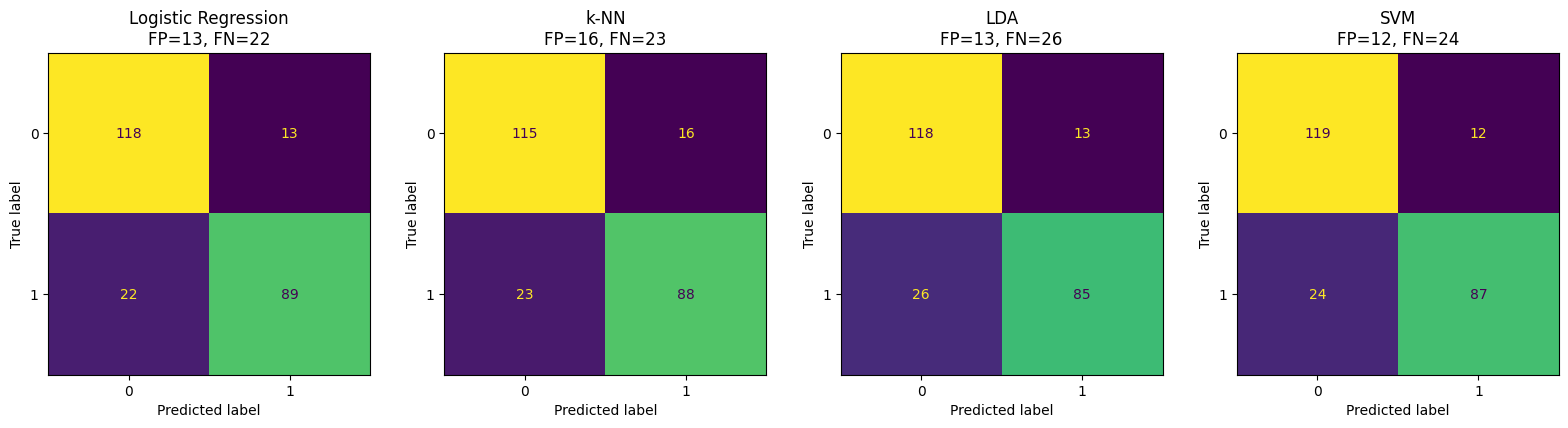

In [32]:
cm_models = {"Logistic Regression": candidates["Logistic Regression"],
             "k-NN": candidates["k-NN"],
             "LDA": candidates["LDA"],
             "SVM": candidates["SVM"]}

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, (name, pipe) in zip(axes, cm_models.items()):
    pred = cross_val_predict(pipe, X_train, y_train, cv=cv, n_jobs=1)
    cm = confusion_matrix(y_train, pred)
    ConfusionMatrixDisplay(cm, display_labels=[0, 1]).plot(ax=ax, colorbar=False)
    tn, fp, fn, tp = cm.ravel()
    ax.set_title(f"{name}\nFP={fp}, FN={fn}")
plt.tight_layout()
plt.show()

## Фіксація фінальної моделі
Фінальною обрано логістичну регресію (L2, C = 10, solver = liblinear, max_iter = 2000, random_state = 42) зі стандартизацією числових ознак і one-hot-кодуванням категоріальних.

CV F1 = 0,8363, CV ROC AUC = 0,9002, CV Recall = 0,8016. Це найкращі показники серед кандидатів, до того ж std між фолдами найменший (0,0127). Модель проста, швидка й інтерпретована; недолік: лінійна межа рішення.

In [33]:
final_pipeline = Pipeline([
    ("preprocessor", preprocessor_scaled),
    ("classifier", LogisticRegression(penalty="l2", C=10, solver="liblinear",
                                      max_iter=2000, random_state=RANDOM_STATE))
])
final_pipeline.fit(X_train, y_train)
print("Фінальний Pipeline навчено на X_train.")

Фінальний Pipeline навчено на X_train.


Одноразове оцінювання на test

,Фінальна модель,Test Accuracy,Test Precision,Test Recall,Test F1,Test ROC AUC
0,"Logistic Regression (L2, C=10)",0.8689,0.8333,0.8929,0.8621,0.9621


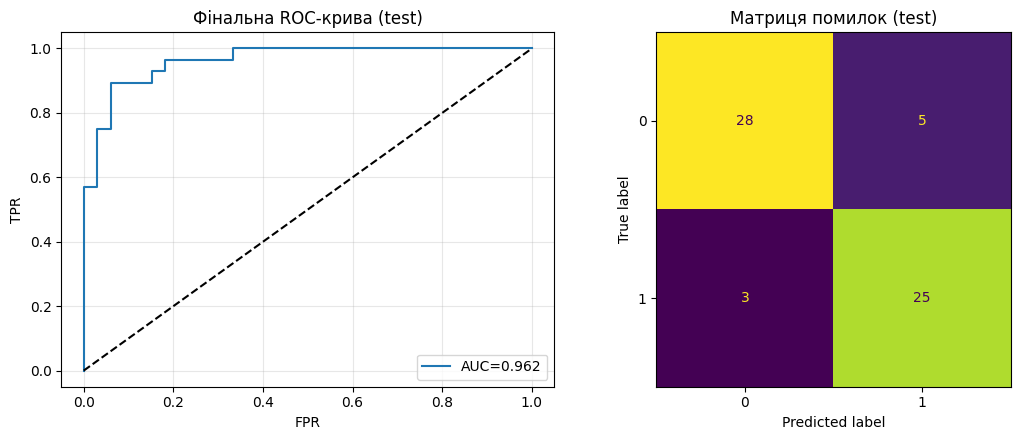

In [34]:
y_pred = final_pipeline.predict(X_test)
y_proba = final_pipeline.predict_proba(X_test)[:, 1]

final_metrics = pd.DataFrame([{
    "Фінальна модель": "Logistic Regression (L2, C=10)",
    "Test Accuracy": accuracy_score(y_test, y_pred),
    "Test Precision": precision_score(y_test, y_pred),
    "Test Recall": recall_score(y_test, y_pred),
    "Test F1": f1_score(y_test, y_pred),
    "Test ROC AUC": roc_auc_score(y_test, y_proba),
}])
display(final_metrics.round(4))
final_metrics.to_csv(REPORTS_DIR / "final_test_metrics.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
fpr, tpr, _ = roc_curve(y_test, y_proba)
axes[0].plot(fpr, tpr, label=f"AUC={final_metrics['Test ROC AUC'].iloc[0]:.3f}")
axes[0].plot([0, 1], [0, 1], "k--")
axes[0].set_xlabel("FPR"); axes[0].set_ylabel("TPR")
axes[0].set_title("Фінальна ROC-крива (test)"); axes[0].legend(); axes[0].grid(alpha=0.3)
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred), display_labels=[0, 1]).plot(ax=axes[1], colorbar=False)
axes[1].set_title("Матриця помилок (test)")
plt.tight_layout(); plt.show()

Аналіз помилкових test-прогнозів

In [35]:
errors = X_test.copy()
errors["Справжній клас"] = y_test
errors["Прогноз"] = y_pred
errors["P(клас 1)"] = y_proba.round(3)
errors = errors[errors["Справжній клас"] != errors["Прогноз"]]
display(errors)

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,Справжній клас,Прогноз,P(клас 1)
271,66.0,1.0,4.0,160.0,228.0,0.0,2.0,138.0,0.0,2.3,1.0,0.0,6.0,0,1,0.516
196,69.0,1.0,1.0,160.0,234.0,1.0,2.0,131.0,0.0,0.1,2.0,1.0,3.0,0,1,0.709
33,59.0,1.0,4.0,135.0,234.0,0.0,0.0,161.0,0.0,0.5,2.0,0.0,7.0,0,1,0.781
292,44.0,1.0,4.0,120.0,169.0,0.0,0.0,144.0,1.0,2.8,3.0,0.0,6.0,1,0,0.411
287,58.0,1.0,2.0,125.0,220.0,0.0,0.0,144.0,0.0,0.4,2.0,NaN,7.0,0,1,0.597
66,60.0,1.0,3.0,140.0,185.0,0.0,2.0,155.0,0.0,3.0,2.0,0.0,3.0,1,0,0.249
92,62.0,1.0,3.0,130.0,231.0,0.0,0.0,146.0,0.0,1.8,2.0,3.0,7.0,0,1,0.925
172,59.0,0.0,4.0,174.0,249.0,0.0,0.0,143.0,1.0,0.0,2.0,0.0,3.0,1,0,0.462


Збереження та перевірка joblib

In [36]:
MODEL_PATH = MODELS_DIR / "best_classifier.joblib"
joblib.dump(final_pipeline, MODEL_PATH)
print("Файл створено:", MODEL_PATH.exists())

loaded = joblib.load(MODEL_PATH)
print(loaded.predict(X_test.head(3)))
print("Збігається з оригіналом:",
      (loaded.predict(X_test) == final_pipeline.predict(X_test)).all())

Файл створено: True
[0 1 0]
Збігається з оригіналом: True


## Загальний висновок

У мініпроєкті порівняно шість класичних моделей бінарної класифікації (логістична регресія, k-NN, GaussianNB, LDA, QDA, SVM) на наборі Heart Disease (Cleveland, 303 об'єкти). Усі моделі побудовано як Pipeline з однаковим препроцесингом, порівняно за єдиною 5-кратною StratifiedKFold лише на навчальній вибірці (242 об'єкти). Тестова вибірка (61 об'єкт) використана один раз для зафіксованої фінальної моделі.

**Вплив масштабування.**
- Логістична регресія: якість не змінилася (CV F1 = 0,8245), але стандартизація прискорила збіжність: 18 ітерацій проти 1238.
- k-NN: масштабування критичне: CV F1 зріс з 0,512 до 0,799, бо без нього ознаки з великим діапазоном (chol, thalach) домінують у відстані.

**Параметри моделей.**
- k-NN: найкраще k = 3 з манхеттенською відстанню (CV F1 = 0,8175). Різниця між сусідніми k та між відстанями менша за std між фолдами.
- Логістична регресія: найкраща L2, C = 10 (CV F1 = 0,8363). За C = 0,01 L1 занулює всі коефіцієнти (F1 = 0).
- SVM: найкраща RBF, C = 10, gamma = 0,01 (CV F1 = 0,8270). Перевага над лінійною SVM (0,8025) менша за std, тобто статистично незначуща.

**Ймовірнісні моделі.**
- Найстабільнішою була LDA (CV F1 = 0,8128, ROC AUC = 0,8993, без попереджень).
- QDA при reg_param = 0 працювала нестабільно: 10 попереджень про виродження коваріаційної матриці, F1 = 0,571, std = 0,143. Причина: стовпці one-hot-кодування лінійно залежні. При reg_param = 0,1 QDA стабільна (F1 = 0,7962).
- GaussianNB має найвищий Recall (0,846), але найнижчий F1 (0,7495) через порушення нормальності та залежність ознак.

**Вибір фінальної моделі.** Найкращий CV F1 і ROC AUC має логістична регресія (L2, C = 10): F1 = 0,8363, ROC AUC = 0,9002, Recall = 0,8016, std F1 = 0,0127 (найменший серед кандидатів). Її зафіксовано як фінальну до відкриття test: вона найточніша за CV, найстабільніша, проста та інтерпретована.

**Результат на test (одноразово).** Accuracy = 0,869, Precision = 0,833, Recall = 0,893, F1 = 0,862, ROC AUC = 0,962. З 61 об'єкта помилково класифіковано 8 (5 хибно позитивних, 3 хибно негативних).

**Узгодженість із крос-валідацією.** Test-результат узгоджується з CV і навіть трохи вищий. Це не означає, що модель краща, ніж очікувалось: test малий, тому оцінка шумна, і один-два прогнози помітно змінюють метрики. Після перегляду test модель не змінювалась.

**Обмеження експерименту.**
- Один набір даних і один split на 61 test-об'єкт, тож оцінка узагальнення неточна.
- Різниці між кращими кандидатами (LogReg, SVM, k-NN, LDA) менші за std між фолдами, тому вибір фінальної моделі не є статистично суворим.
- Не використано nested cross-validation.
- Сітки гіперпараметрів невеликі.
- Результати навчальні й не є медичним діагнозом.

## Відповіді на контрольні запитання
**1. Для чого використовується Pipeline?**
Об'єднує попередню обробку і модель в один об'єкт. Усі перетворення навчаються лише на train-фолдах, тому немає витоку даних, а код відтворюваний.

**2. Яку проблему вирішує ColumnTransformer?**
Дозволяє застосовувати різну обробку до різних стовпців: числові і категоріальні.

**3. Чому train/test split потрібно виконувати до навчання імпутації та масштабування?**
Інакше медіани, середні й std рахуються з урахуванням тестових даних. Це витік інформації, і оцінка якості виходить завищеною.

**4. Чому числові й категоріальні ознаки обробляються по-різному?**
Числові мають кількісну шкалу, їх можна масштабувати. Категоріальні є лише кодами категорій.

**5. Що означає handle_unknown="ignore"?**
Якщо в test або в нових даних зустрінеться категорія, якої не було в train, кодувальник не видасть помилку, а поставить нулі в усіх її one-hot-стовпцях.

**6. Чому для GaussianNB, LDA і QDA зручно отримувати щільну матрицю?**
Ці моделі не працюють із розрідженими матрицями. sparse_output=False одразу дає звичайний масив, сумісний з ними.

**7. Чому масштабування важливе для логістичної регресії, k-NN і SVM?**
k-NN і SVM залежать від відстаней, тому ознаки з великим діапазоном домінують. Для логістичної регресії масштаб впливає на регуляризацію та швидкість збіжності.

**8. Що контролює параметр C у логістичній регресії?**
Силу регуляризації (обернено): мале C означає сильну регуляризацію (ризик недонавчання), велике C означає слабку (ризик перенавчання).

**9. Чим L1-регуляризація відрізняється від L2?**
L1 штрафує суму модулів коефіцієнтів і може занулювати частину з них. L2 штрафує суму квадратів, зменшує коефіцієнти, але не занулює.

**10. Як значення k впливає на k-NN?**
Мале k дає складну, шумну межу (ризик перенавчання), велике k згладжує межу (ризик недонавчання).

**11. Чому k-NN чутливий до масштабу ознак?**
Він рахує відстані між об'єктами, тому ознаки з великими значеннями визначають сусідів, а ознаки з малим діапазоном майже не впливають.

**12. Які припущення використовує Gaussian Naive Bayes?**
Ознаки умовно незалежні за відомого класу, а кожна числова ознака в межах класу має нормальний розподіл.

**13. Чим LDA відрізняється від QDA?**
LDA використовує спільну коваріаційну матрицю для всіх класів і дає лінійну межу. QDA використовує окрему матрицю для кожного класу й дає криволінійну межу, але має більше параметрів.

**14. Чому QDA може бути нестабільною?**
Потрібно оцінити окрему коваріаційну матрицю для кожного класу, а об'єктів мало. Після one-hot-кодування стовпці лінійно залежні, і матриця вироджується. Допомагає reg_param.

**15. Що означає параметр C у SVM?**
Компроміс між шириною розділювальної смуги та штрафом за помилки на train: мале C дає м'якший штраф (ризик недонавчання), велике C штрафує помилки сильно (ризик перенавчання).

**16. Що означає параметр gamma?**
У RBF-ядрі визначає, наскільки локальним є вплив одного об'єкта. Мале gamma дає гладку межу, велике gamma дає звивисту межу й ризик перенавчання.

**17. Для чого використовується GridSearchCV?**
Перебирає задану сітку гіперпараметрів, оцінює кожну комбінацію крос-валідацією і повертає найкращу за обраною метрикою.

**18. Що таке StratifiedKFold?**
Крос-валідація, яка ділить дані на частини зі збереженням співвідношення класів у кожній. Це потрібно для чесного порівняння моделей.

**19. Чому пошук параметрів не можна виконувати на тестовій вибірці?**
Тоді test впливає на вибір моделі й перестає бути незалежним, а оцінка узагальнення стає завищеною.

**20. Чому не можна вибирати найкращий алгоритм за Test F1 кількох моделей?**
Це перетворює test на частину процесу вибору: ми підганяємось під цю вибірку, і фінальна оцінка стає оптимістичною.

**21. Що таке позавибірковий прогноз `cross_val_predict`?**
Прогноз для кожного train-об'єкта, зроблений моделлю, яка його не бачила під час навчання. Дає чесні ймовірності й дозволяє будувати ROC та матриці помилок без test.

**22. Що показує ROC-крива?**
Залежність частки виявлених позитивних від частки хибних тривог за різних порогів класифікації. Чим ближче крива до лівого верхнього кута, тим краще.

**23. Що означає ROC AUC?**
Площа під ROC-кривою: ймовірність того, що випадковий позитивний об'єкт отримає вищу оцінку, ніж випадковий негативний. 0,5 означає випадкове вгадування, 1 означає ідеальне розділення.

**24. Чому позитивний клас потрібно визначити явно?**
Precision, Recall і F1 рахуються саме для позитивного класу. Без явного визначення метрики можна інтерпретувати неправильно.

**25. Чому найкраща за accuracy модель не завжди є найкращою практично?**
Accuracy не показує типи помилок. У медичній задачі пропустити хворого гірше, ніж помилково тривожити, тому важливі Recall, F1, ROC AUC. Також accuracy оманлива за незбалансованих класів.

**26. Чому фінальну модель потрібно зафіксувати до відкриття test?**
Щоб test не вплинув на вибір. Якщо дивитися test і потім змінювати модель, він стає частиною навчання й втрачає роль незалежної перевірки.

**27. Що робити, якщо test-результат виявився гіршим за CV?**
Не змінювати модель, а чесно описати це як оцінку узагальнення й проаналізувати причини. Новий цикл розробки потребував би нового незалежного тесту.

**28. Чому потрібно зберігати весь Pipeline?**
Щоб нові дані проходили той самий препроцесинг із параметрами, навченими на train. Тоді predict працює на сирих даних без ручних кроків.

**29. Для чого потрібна окрема Git-гілка?**
Щоб розробляти проєкт ізольовано, не псуючи main, мати чисту історію змін і можливість безпечних експериментів.

**30. Для чого створюється Pull Request?**
Щоб оформити злиття гілки в main: показати всі зміни, перевірити файли, обговорити їх і лише потім об'єднати.